# Video Game Sales Prediction on Steam Data
## Notebook 2 of 3 — Exploratory Analysis

This notebook describes the modeling table produced in Notebook 1 before any model is fitted: the
distribution of each feature and of the target, how sales vary over time, and how each feature
relates to sales. The findings indicate which characteristics of the data are likely to affect
the models in Notebook 3.

In [1]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, GREEN, RED, GREY = "#4C72B0", "#55A868", "#C44E52", "#8C8C8C"

def range_label(text):
    # "20000 - 50000" -> "20k–50k"; "1000000 - 2000000" -> "1M–2M"
    def short(n):
        n = int(n)
        if n >= 1_000_000:
            return f"{n // 1_000_000}M"
        return f"{n // 1000}k" if n >= 1000 else str(n)
    lo, hi = text.split(" - ")
    return f"{short(lo)}–{short(hi)}"


FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")

data = pd.read_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), parse_dates=["release_dt"])
with open(os.path.join(DATA_DIR, "features.json")) as f:
    spec = json.load(f)
TARGET = spec["target"]
NUMERIC = spec["numeric"]
FLAGS = spec["genres"] + spec["categories"]
print(f"{len(data):,} games | {len(NUMERIC)} numeric features | {len(FLAGS)} binary features")

76,727 games | 9 numeric features | 33 binary features


---
# 4. Analysis

## 4.1 Descriptive statistics

Table 1 follows the format of the parent paper's feature statistics table.

In [2]:
labels = {
    "price": "Price (USD)", "release_year": "Release year", "required_age": "Required age",
    "n_languages": "Supported languages", "n_audio_languages": "Full-audio languages",
    "mac": "Mac support (0/1)", "linux": "Linux support (0/1)", "n_screenshots": "Screenshots",
    "description_length": "Description length (characters)", TARGET: "Owners, millions (target)",
}
rows = []
for col, label in labels.items():
    s = data[col]
    rows.append({"Feature": label, "Mean": s.mean(), "Mode": s.mode().iloc[0], "Median": s.median(),
                 "Min": s.min(), "Max": s.max(), "Missing": f"{s.isna().sum()} ({s.isna().mean():.0%})"})
table1 = pd.DataFrame(rows).set_index("Feature")
table1.to_csv(os.path.join(TAB_DIR, "table1_descriptive_statistics.csv"))
table1.style.format({"Mean": "{:,.3f}", "Mode": "{:,.2f}", "Median": "{:,.2f}", "Min": "{:,.2f}", "Max": "{:,.2f}"}) \
    .set_caption("Table 1. Descriptive statistics")

,Mean,Mode,Median,Min,Max,Missing
Feature,,,,,,
Price (USD),8.062,4.99,4.99,0.00,999.98,0 (0%)
Release year,"2,019.970","2,023.00","2,020.00","1,997.00","2,024.00",0 (0%)
Required age,0.244,0.00,0.00,0.00,21.00,0 (0%)
Supported languages,4.484,1.00,1.00,0.00,103.00,0 (0%)
Full-audio languages,1.620,0.00,0.00,0.00,103.00,0 (0%)
Mac support (0/1),0.205,0.00,0.00,0.00,1.00,0 (0%)
Linux support (0/1),0.146,0.00,0.00,0.00,1.00,0 (0%)
Screenshots,9.039,5.00,7.00,0.00,183.00,0 (0%)
Description length (characters),"1,298.424",364.00,"1,051.00",0.00,"89,638.00",0 (0%)


**Observations.**
- No feature has missing values.
- The typical game is small: the median game is priced at $4.99, supports one language, has no full-audio localisation, runs only on Windows and has seven screenshots. Means are higher than medians for price, languages and description length because a minority of large productions pulls them up.
- Most games are recent: the median release year is 2020, although the data reach back to 1997.
- The target ranges from 0.01 million (the midpoint of the lowest range) to 150 million owners. Its median equals its minimum, while its mean is more than twelve times larger.

## 4.2 Distribution of the target

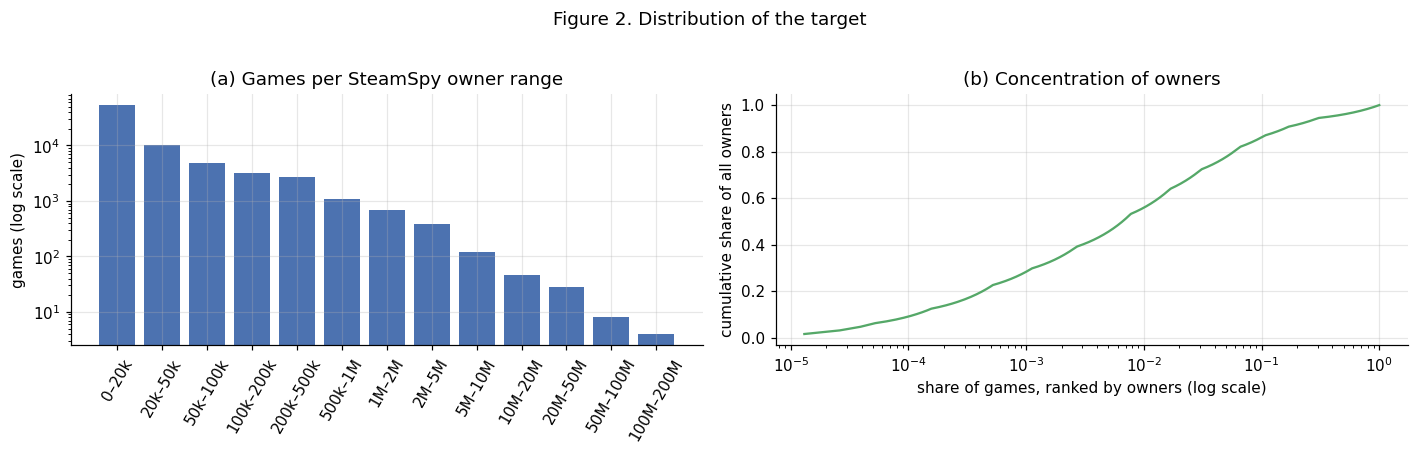

Games in the lowest range (<20k owners): 69.7%
Share of all owners held by the top 1% of games: 55.9%
Share of all owners held by the top 10% of games: 86.1%
Skewness of the target: 59.8


In [3]:
order = data.drop_duplicates("estimated_owners").sort_values(TARGET)["estimated_owners"].tolist()
counts = data["estimated_owners"].value_counts().reindex(order)
tick_labels = [range_label(o) for o in order]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(tick_labels, counts.values, color=BLUE)
axes[0].set_yscale("log")
axes[0].set_ylabel("games (log scale)")
axes[0].set_title("(a) Games per SteamSpy owner range")
axes[0].tick_params(axis="x", rotation=60)

owners_sorted = np.sort(data[TARGET].values)[::-1]
cum_share = np.cumsum(owners_sorted) / owners_sorted.sum()
axes[1].plot(np.arange(1, len(owners_sorted) + 1) / len(owners_sorted), cum_share, color=GREEN)
axes[1].set_xscale("log")
axes[1].set_xlabel("share of games, ranked by owners (log scale)")
axes[1].set_ylabel("cumulative share of all owners")
axes[1].set_title("(b) Concentration of owners")
fig.suptitle("Figure 2. Distribution of the target", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig02_target_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

n = len(owners_sorted)
print(f"Games in the lowest range (<20k owners): {(data[TARGET] == 0.01).mean():.1%}")
print(f"Share of all owners held by the top 1% of games: {owners_sorted[: n // 100].sum() / owners_sorted.sum():.1%}")
print(f"Share of all owners held by the top 10% of games: {owners_sorted[: n // 10].sum() / owners_sorted.sum():.1%}")
print(f"Skewness of the target: {data[TARGET].skew():.1f}")

**Observations.** About 70% of games fall in the lowest owner range (fewer than 20,000 owners). At the other extreme, the top 1% of games account for 56% of all owners and the top 10% for 86%. The skewness of 59.8 (a symmetric distribution has 0) confirms an extremely long right tail.

**Implication for modeling.** Squared-error measures (MSE, RMSE, R²), and the least-squares fitting used by Linear Regression, weight each error by its square. With this distribution they will be dominated by the few hundred largest games, so a model can score well by approximating the blockbusters while predicting the typical game poorly, or badly because of a single missed blockbuster. Following the parent paper, the target is kept on its original scale for the baseline; the consequences are examined in Notebook 3.

## 4.3 Sales over time

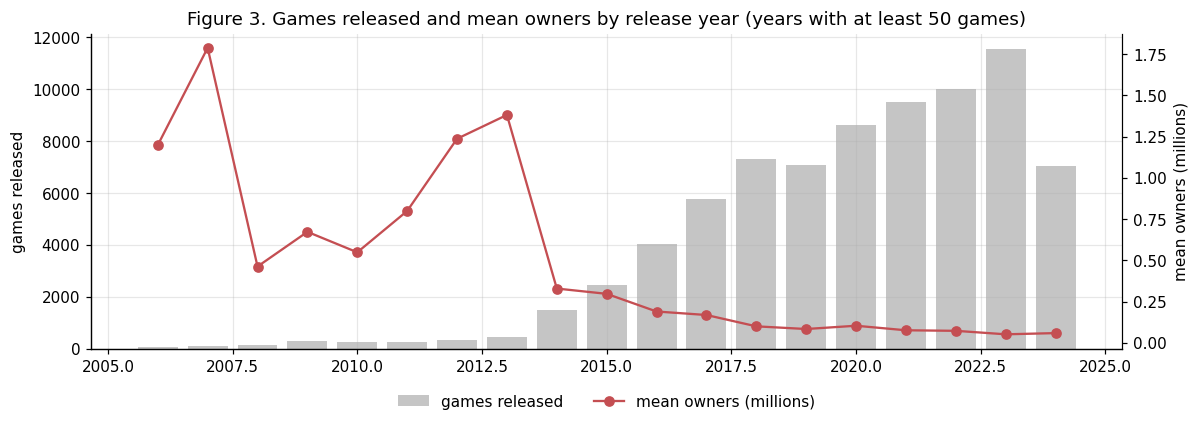

release_year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
games,69.000,90.000,157.000,309.000,254.000,260.000,317.000,436.000,1485.000,2454.000,4024.000,5747.000,7305.00,7082.000,8615.000,9497.000,10010.000,11564.000,7024.000
mean_owners,1.198,1.788,0.462,0.672,0.548,0.799,1.237,1.381,0.329,0.297,0.190,0.168,0.10,0.083,0.103,0.076,0.072,0.051,0.059
median_owners,0.150,0.550,0.150,0.075,0.075,0.150,0.350,0.350,0.075,0.035,0.035,0.010,0.01,0.010,0.010,0.010,0.010,0.010,0.010


In [4]:
by_year = data.groupby("release_year").agg(games=("appid", "size"), mean_owners=(TARGET, "mean"),
                                           median_owners=(TARGET, "median"))
by_year = by_year[by_year["games"] >= 50]

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(by_year.index, by_year["games"], color=GREY, alpha=0.5, label="games released")
ax1.set_ylabel("games released")
ax2 = ax1.twinx()
ax2.plot(by_year.index, by_year["mean_owners"], color=RED, marker="o", label="mean owners (millions)")
ax2.set_ylabel("mean owners (millions)")
ax2.grid(False)
ax2.spines["right"].set_visible(True)
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, [l.get_label() for l in lines], loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
ax1.set_title("Figure 3. Games released and mean owners by release year (years with at least 50 games)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig03_sales_by_year.png"), dpi=150, bbox_inches="tight")
plt.show()
by_year.round(3).T

**Observations.** Annual releases grew from fewer than 500 before 2014 to more than 10,000 from 2022. Mean owners per game fell from 0.46–1.79 million for games released in 2006–2013 to 0.05–0.10 million from 2019, and the median has been at the lowest range since 2017. Two effects combine: older games have had more years to accumulate owners, and the market has become far more crowded. Release year therefore captures time on sale as much as any property of the games. It is included as a feature, as in the parent paper.

## 4.4 Relationship between features and sales

Two correlation measures are reported for each numeric feature. **Pearson** correlation measures
linear association and is the relationship a Linear Regression model can use directly. **Spearman**
correlation measures whether larger values tend to go with larger sales, regardless of the shape of
the relationship, and is less affected by extreme values.

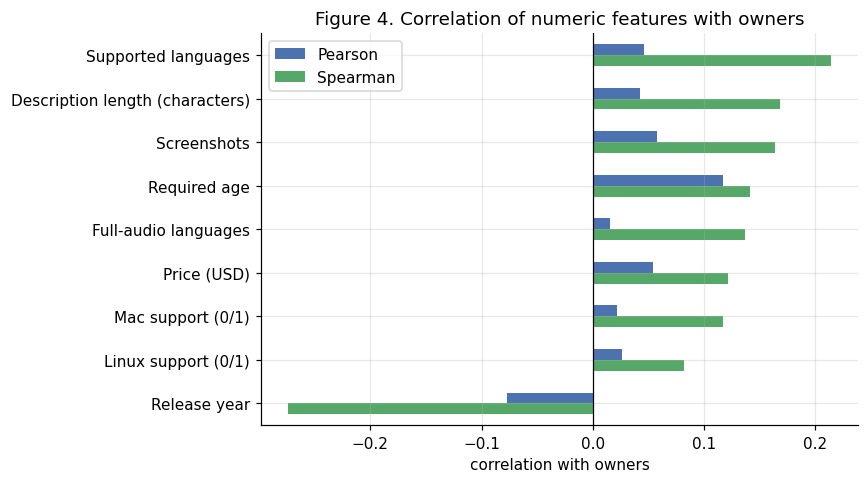

,Pearson,Spearman
Supported languages,0.046,0.214
Description length (characters),0.042,0.168
Screenshots,0.058,0.164
Required age,0.117,0.141
Full-audio languages,0.015,0.136
Price (USD),0.054,0.121
Mac support (0/1),0.022,0.117
Linux support (0/1),0.026,0.082
Release year,-0.077,-0.274


In [5]:
corr = pd.DataFrame({
    "Pearson": [data[c].corr(data[TARGET]) for c in NUMERIC],
    "Spearman": [data[c].corr(data[TARGET], method="spearman") for c in NUMERIC],
}, index=[labels[c] for c in NUMERIC]).sort_values("Spearman", ascending=False)
corr.to_csv(os.path.join(TAB_DIR, "table2_correlation_with_target.csv"))

ax = corr.plot(kind="barh", figsize=(8, 4.5), color=[BLUE, GREEN])
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("correlation with owners")
ax.set_title("Figure 4. Correlation of numeric features with owners")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig04_feature_target_correlation.png"), dpi=150)
plt.show()
corr.round(3).style.format("{:.3f}").set_caption("Table 2. Correlation with owners")

**Observations.** All Pearson correlations with owners are weak (at most 0.12 in absolute value), while Spearman correlations are noticeably larger: release year −0.27, supported languages 0.21, description length 0.17, screenshots 0.16. The difference arises because the extreme values of the target dominate the Pearson coefficient. The features are related to sales for the typical game, as the Spearman values show, but the relationship is not linear on the original owner scale. Linear Regression can use only the linear part and is therefore expected to explain little of the variance.

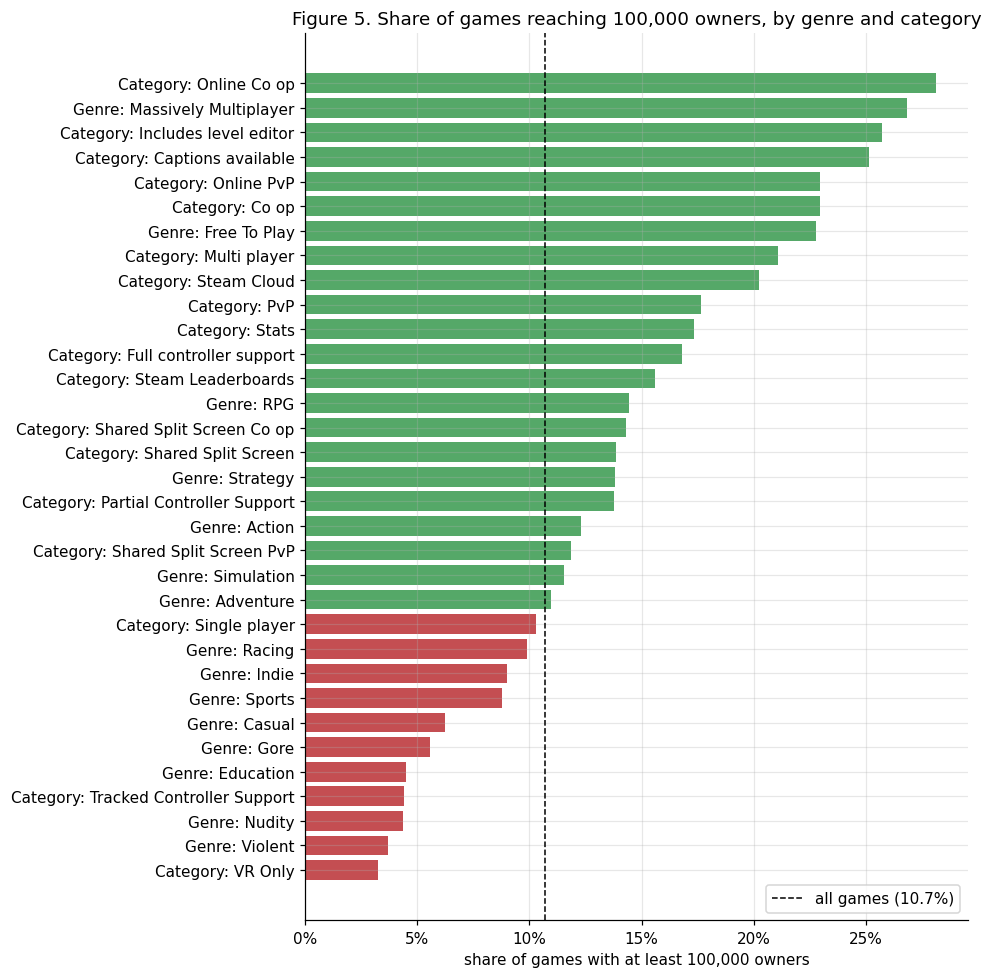

In [6]:
flag_rows = []
for c in FLAGS:
    on = data[c] == 1
    flag_rows.append({"feature": c.replace("genre_", "Genre: ").replace("cat_", "Category: ").replace("_", " "),
                      "share of games": on.mean(), "median owners (flag = 1)": data.loc[on, TARGET].median(),
                      "share >= 100k owners (flag = 1)": (data.loc[on, TARGET] >= 0.15).mean()})
flags = pd.DataFrame(flag_rows).set_index("feature").sort_values("share >= 100k owners (flag = 1)")
overall = (data[TARGET] >= 0.15).mean()

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(flags.index, flags["share >= 100k owners (flag = 1)"], color=np.where(flags["share >= 100k owners (flag = 1)"] >= overall, GREEN, RED))
ax.axvline(overall, color="black", ls="--", lw=1, label=f"all games ({overall:.1%})")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("share of games with at least 100,000 owners")
ax.set_title("Figure 5. Share of games reaching 100,000 owners, by genre and category")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig05_genre_category_sales.png"), dpi=150)
plt.show()

**Observations.** Across all games, 10.7% reach at least 100,000 owners. Online co-op (28%), massively multiplayer (27%), level-editor support (26%), online PvP and co-op (23% each) and free-to-play (23%) are associated with the highest rates. The most common flags sit near or below the average (Single-player 10%, Indie 9%, Casual 6%), because they describe the bulk of small releases. VR-only games have the lowest rate (3%). Several flags, such as Violent, Nudity and Education, apply to fewer than 1% of games, so their rates are based on small samples.

## 4.5 Correlation among features

Strongly correlated features make Linear Regression coefficients unstable and difficult to
interpret, although they do not necessarily reduce predictive accuracy.

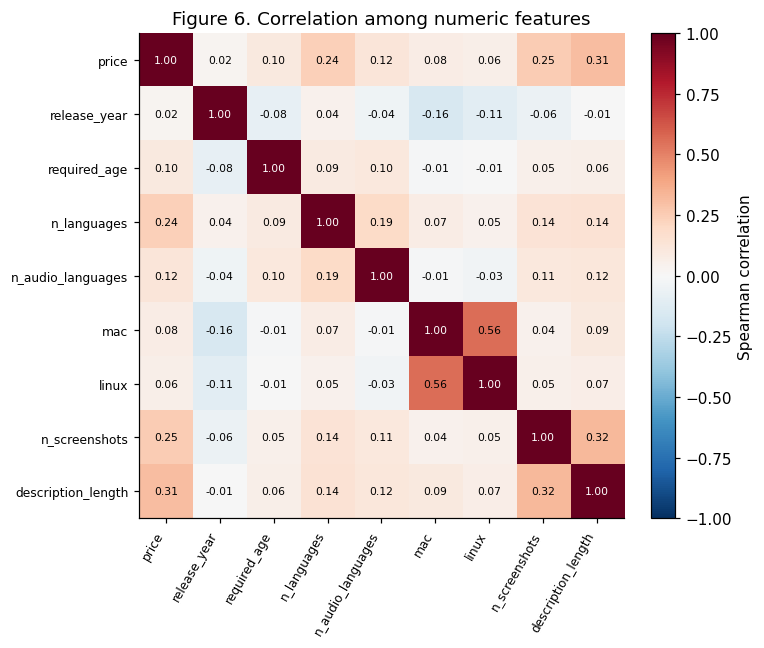

In [7]:
fc = data[NUMERIC].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(fc, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC)))
ax.set_xticklabels(NUMERIC, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(NUMERIC)))
ax.set_yticklabels(NUMERIC, fontsize=8)
for i in range(len(NUMERIC)):
    for j in range(len(NUMERIC)):
        ax.text(j, i, f"{fc.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(fc.iloc[i, j]) > 0.6 else "black")
ax.grid(False)
plt.colorbar(im, fraction=0.046, pad=0.04, label="Spearman correlation")
ax.set_title("Figure 6. Correlation among numeric features")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig06_feature_correlation.png"), dpi=150)
plt.show()

**Observations.** Correlations among the numeric features are low. The only notable pair is Mac and Linux support (ρ = 0.56), since games that support one platform often support both. No pair is strong enough to make the Linear Regression coefficients unstable.

## Summary of Notebook 2

- The target is extremely skewed: 70% of games are in the lowest owner range, and 1% of games hold more than half of all owners.
- Sales fall with release year, reflecting both time on sale and a growing number of competing releases.
- The features are related to sales in rank terms (Spearman up to 0.27) but only weakly in linear terms (Pearson at most 0.12).
- Multiplayer and online design, free-to-play and broader localisation are associated with higher sales; casual, single-player and VR-only titles with lower sales.
- Collinearity among features is low.